In [1]:
import numpy as np
import matplotlib.pyplot as plt

!pip install tiktoken
import tiktoken

In [2]:
tokenizer = tiktoken.get_encoding("cl100k_base")
dir(tokenizer)
type(tokenizer)

tiktoken.core.Encoding

In [3]:
#number of tokens in the tokenizer
tokenizer.n_vocab

100277

In [4]:
tokenizer.decode([tokenizer.eot_token])  # should be an empty string

'<|endoftext|>'

In [5]:
#tokenizer.decode([100261])

In [6]:
for i in range(1000, 1050):
    print(i, tokenizer.decode([i]))
#(type(i))    

1000 indow
1001 lement
1002 pect
1003 ash
1004 [i
1005  use
1006 .F
1007 pec
1008  ad
1009 ove
1010 ception
1011 ength
1012 include
1013 ader
1014                            
1015 atus
1016 Th
1017 itle
1018 rit
1019 void
1020 ().
1021 (

1022  off
1023  other
1024  &&
1025 ';

1026 ms
1027  been
1028  te
1029 ml
1030 co
1031 nc
1032 13
1033 ervice
1034  %
1035 **

1036 ann
1037 ade
1038 




1039 lock
1040 const
1041 100
1042 ponse
1043  sup
1044 ++
1045 date
1046  acc
1047  had
1048  bu
1049 200


In [7]:
tokenizer.decode([12345]) 

' democr'

In [8]:
text = "My name is Mike and I like toothpaste-flavored chocolate."
tokens = tokenizer.encode(text)
print(tokens)

[5159, 836, 374, 11519, 323, 358, 1093, 26588, 57968, 12556, 76486, 18414, 13]


In [9]:
text.split()

['My',
 'name',
 'is',
 'Mike',
 'and',
 'I',
 'like',
 'toothpaste-flavored',
 'chocolate.']

In [10]:
for word in text.split():
  print(f'"{word}" comprises token(s) {tokenizer.encode(word)}')

"My" comprises token(s) [5159]
"name" comprises token(s) [609]
"is" comprises token(s) [285]
"Mike" comprises token(s) [35541]
"and" comprises token(s) [438]
"I" comprises token(s) [40]
"like" comprises token(s) [4908]
"toothpaste-flavored" comprises token(s) [998, 8942, 57968, 12556, 76486]
"chocolate." comprises token(s) [331, 14136, 13]


In [11]:
for t in tokens:
  print(f'Token {t:>6} is "{tokenizer.decode([t])}"')

Token   5159 is "My"
Token    836 is " name"
Token    374 is " is"
Token  11519 is " Mike"
Token    323 is " and"
Token    358 is " I"
Token   1093 is " like"
Token  26588 is " tooth"
Token  57968 is "paste"
Token  12556 is "-fl"
Token  76486 is "avored"
Token  18414 is " chocolate"
Token     13 is "."


[ 1.  1.  1. ... nan nan 15.]


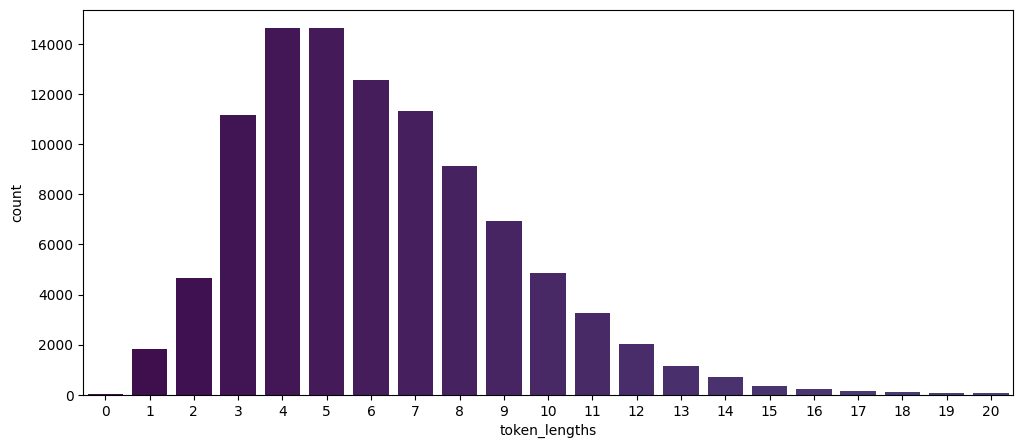

In [12]:
# initialize lengths vector
token_lengths = np.zeros(tokenizer.n_vocab)

# get the number of characters in each token
for idx in range(tokenizer.n_vocab):
  try:
    token_lengths[idx] = len(tokenizer.decode([idx]))
  except:
    token_lengths[idx] = np.nan

# count unique lengths
uniqueLengths,tokenCount = np.unique(token_lengths,return_counts=True)
print(token_lengths)

import pandas as pd
df = pd.DataFrame({'token_lengths': token_lengths})
df.head(50)

df['token_lengths'] = df['token_lengths'].fillna(0).astype(int)
#df.countplot(x='token_lengths', kind='hist', bins=50, title='Token Length Distribution', xlabel='Token Length', ylabel='Count')
df.head()
df
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
sns.countplot(x='token_lengths', hue='token_lengths', data=df, palette='viridis', order=range(0, 21), legend=False)
plt.show()

# i was exploring to know if there is only but two classes in this data in the above plot

_______________________________________________________

# visualize

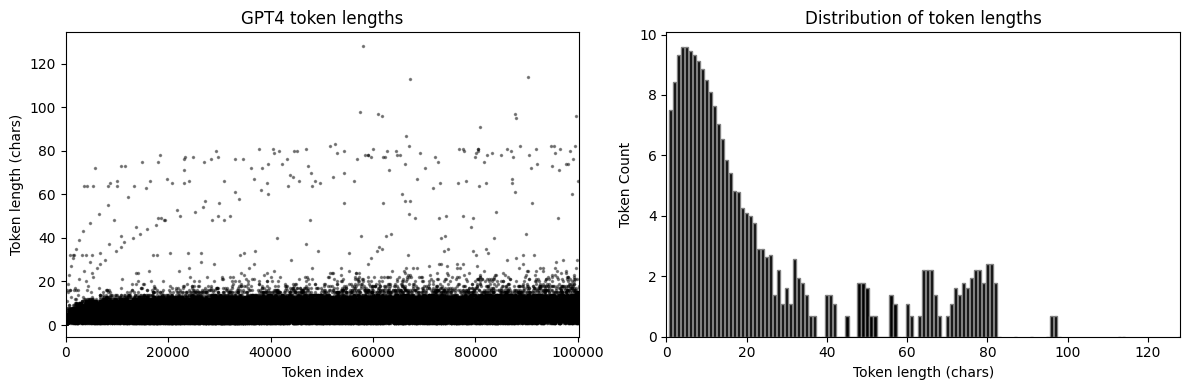

In [13]:
# visualize
_,axs = plt.subplots(1,2,figsize=(12,4))
axs[0].plot(token_lengths,'k.',markersize=3,alpha=.4)
axs[0].set(xlim=[0,tokenizer.n_vocab],xlabel='Token index',ylabel='Token length (chars)',title='GPT4 token lengths')

axs[1].bar(uniqueLengths,np.log(tokenCount),color='k',edgecolor='gray')
axs[1].set(xlim=[0,max(uniqueLengths)],xlabel='Token length (chars)',ylabel='Token Count',title='Distribution of token lengths')

plt.tight_layout()
plt.show()

In [14]:
# single-token words with vs. without spaces
print( tokenizer.encode(' Michael') )
print( tokenizer.encode('Michael') )

[8096]
[26597]


In [15]:
# multi-token words without a space
print( tokenizer.encode(' Peach') )
print( tokenizer.encode('Peach') )

[64695]
[47, 9739]


In [16]:
peach = tokenizer.encode('Peach')
[tokenizer.decode([p]) for p in peach] # this would iterate the tokens for 'Peach' and decode them back to strings

['P', 'each']

In [17]:
import requests
import re

text = requests.get('https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt').text

In [18]:
# split by punctuation
words = re.split(r'([,.:;—?_!"“()\']|--|\s)',text)
words = [item.strip() for item in words if item.strip()]
print(f'There are {len(words)} words.')
words[10000:10050]

There are 260467 words.


['to',
 'see',
 'me',
 'triumph',
 '?',
 'Ay',
 ',',
 'my',
 'dear',
 ',',
 'Such',
 'eyes',
 'the',
 'widows',
 'in',
 'Corioli',
 'wear',
 ',',
 'And',
 'mothers',
 'that',
 'lack',
 'sons',
 '.',
 'MENENIUS',
 ':',
 'Now',
 ',',
 'the',
 'gods',
 'crown',
 'thee',
 '!',
 'CORIOLANUS',
 ':',
 'And',
 'live',
 'you',
 'yet',
 '?',
 'O',
 'my',
 'sweet',
 'lady',
 ',',
 'pardon',
 '.',
 'VOLUMNIA',
 ':',
 'I']

In [32]:
someRandomWords = np.random.choice(words)
print(f'random word is "{(someRandomWords)}" and its corresponding token is: {tokenizer.encode(someRandomWords)}')

random word is "wager" and its corresponding token is: [86, 1435]


In [34]:
for t in words[:20]:
    print(f' token "{t}" has {len(tokenizer.encode(t))} tokens')

 token "First" has 1 tokens
 token "Citizen" has 2 tokens
 token ":" has 1 tokens
 token "Before" has 1 tokens
 token "we" has 1 tokens
 token "proceed" has 2 tokens
 token "any" has 1 tokens
 token "further" has 2 tokens
 token "," has 1 tokens
 token "hear" has 1 tokens
 token "me" has 1 tokens
 token "speak" has 2 tokens
 token "." has 1 tokens
 token "All" has 1 tokens
 token ":" has 1 tokens
 token "Speak" has 1 tokens
 token "," has 1 tokens
 token "speak" has 2 tokens
 token "." has 1 tokens
 token "First" has 1 tokens


In [35]:
# what happens if we just tokenize the raw (unprocessed) text?
tmTokens = tokenizer.encode(text)
print(f'The text has {len(tmTokens):,} tokens and {len(words):,} words.')

The text has 301,829 tokens and 260,467 words.


In [36]:
# check out some tokens

for t in tmTokens[9990:10020]:
  print(f'Token {t:>6}: "{tokenizer.decode([t])}"')

Token   7636: " alone"
Token     11: ","
Token  28146: " sir"
Token    382: ".

"
Token     44: "M"
Token    965: "EN"
Token    965: "EN"
Token     40: "I"
Token   2078: "US"
Token    512: ":
"
Token     40: "I"
Token   1440: " know"
Token    499: " you"
Token    649: " can"
Token    656: " do"
Token   1633: " very"
Token   2697: " little"
Token   7636: " alone"
Token     26: ";"
Token    369: " for"
Token    701: " your"
Token   8779: " helps"
Token    198: "
"
Token    548: "are"
Token   1690: " many"
Token     11: ","
Token    477: " or"
Token    775: " else"
Token    701: " your"
Token   6299: " actions"


In [37]:
print(tokenizer.decode(tmTokens[9990:10020]))

 alone, sir.

MENENIUS:
I know you can do very little alone; for your helps
are many, or else your actions
